## Importing Libraries

In [56]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
import joblib

## Loading the Dataset

In [2]:
df = pd.read_csv("titanic.csv")
df.shape

(891, 15)

# 1. Data Understaing


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [4]:
df.isna().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [5]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 2. EDA (Exploratory Data Analysis)


In [8]:
df['survived'].value_counts(normalize=True)

,proportion
survived,
0,0.616162
1,0.383838


<Axes: xlabel='fare', ylabel='Count'>

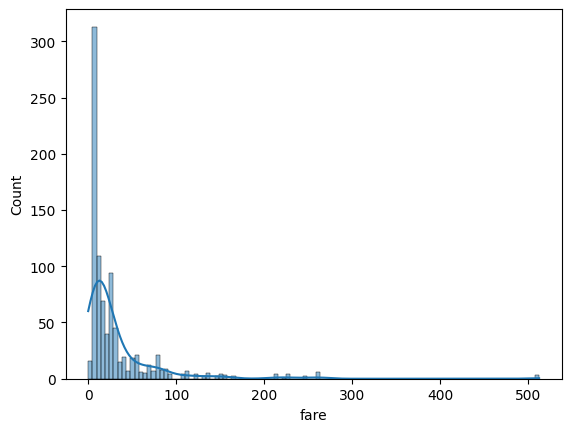

In [9]:
sns.histplot(df['fare'], kde=True)

<Axes: xlabel='fare', ylabel='Count'>

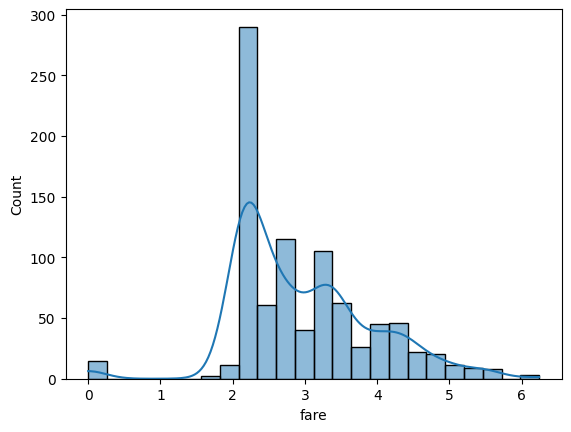

In [12]:
sns.histplot(np.log1p(df['fare']), kde=True)

 Column vs Target

In [13]:
df.groupby('pclass')['survived'].mean()

,survived
pclass,
1,0.629630
2,0.472826
3,0.242363


In [14]:
df.groupby('sex')['survived'].mean()

,survived
sex,
female,0.742038
male,0.188908


In [18]:
df.groupby(df['deck'].isna())['survived'].mean()

,survived
deck,
False,0.669951
True,0.299419


In [16]:
df.groupby(['pclass', 'sex'])['survived'].mean()

pclass  sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: survived, dtype: float64

## 3. Data Cleaning

In [19]:
df['age'] = df['age'].fillna(df['age'].median())

In [20]:
df = df.dropna(subset=['embarked'])
df.shape

(889, 15)

In [21]:
df['deck_missing'] = df['deck'].isna().astype(int)

In [22]:
df = df.drop(columns=['deck', 'embark_town', 'class', 'alive', 'who'])
df.shape

(889, 11)

## 4. Feature Engineering and Encoding

In [28]:
df['fare'] = np.log1p(df['fare'])

In [ ]:
df[['adult_male', 'alone']] = df[['adult_male', 'alone']].astype(int)
df = pd.get_dummies(df, columns=['sex', 'embarked', 'alone'], drop_first=True)
df.shape

In [32]:
df.dtypes

,0
survived,int64
pclass,int64
age,float64
sibsp,int64
parch,int64
fare,float64
alone,int64
deck_missing,int64
sex_male,int64
embarked_Q,int64


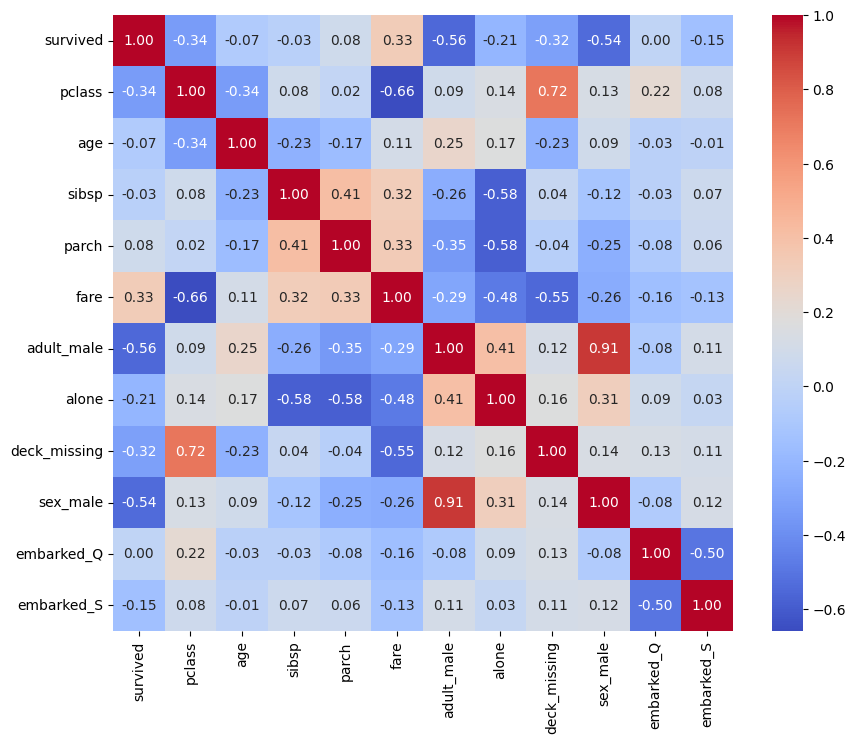

In [26]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

## 5. Feature Selection

In [27]:
df = df.drop(columns=['adult_male'])
df.shape

(889, 11)

## 6. Train-Test Split

In [38]:
X = df.drop(columns='survived')
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train.shape, X_test.shape

((711, 10), (178, 10))

## 7. Model Training

In [41]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
accuracy_score(y_test, lr_pred)

0.8089887640449438

In [43]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
accuracy_score(y_test, rf_pred)

0.797752808988764

## 8. Evaluation

In [47]:
print("LR:", cross_val_score(lr, X, y, cv=5).mean())
print("RF:", cross_val_score(rf, X, y, cv=5).mean())

LR: 0.8031803466006476
RF: 0.8088237161175649


In [50]:


print("LR")
print(confusion_matrix(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

print("RF")
print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

LR
[[94 16]
 [18 50]]
              precision    recall  f1-score   support

           0       0.84      0.85      0.85       110
           1       0.76      0.74      0.75        68

    accuracy                           0.81       178
   macro avg       0.80      0.79      0.80       178
weighted avg       0.81      0.81      0.81       178

RF
[[93 17]
 [19 49]]
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       110
           1       0.74      0.72      0.73        68

    accuracy                           0.80       178
   macro avg       0.79      0.78      0.78       178
weighted avg       0.80      0.80      0.80       178



## 9. Hyperparameter Tuning

In [52]:


params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7, None],
    'min_samples_leaf': [1, 3, 5]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), params, cv=5)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}
0.8270067960208806


In [53]:
best_rf = grid.best_estimator_
best_pred = best_rf.predict(X_test)

print(accuracy_score(y_test, best_pred))
print(confusion_matrix(y_test, best_pred))
print(classification_report(y_test, best_pred))

0.8089887640449438
[[97 13]
 [21 47]]
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.69      0.73        68

    accuracy                           0.81       178
   macro avg       0.80      0.79      0.79       178
weighted avg       0.81      0.81      0.81       178



## 10. Feature Importance and Saving the Model

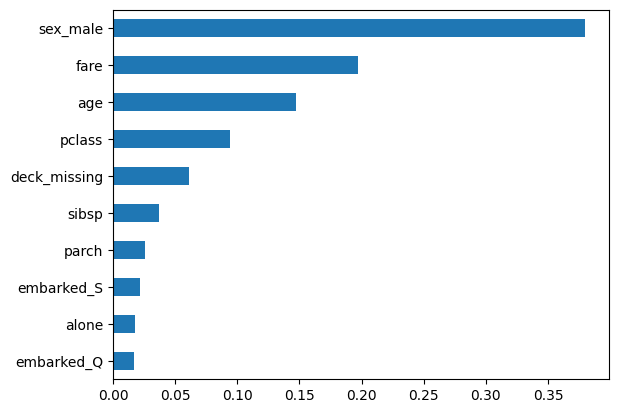

In [54]:
imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh')
plt.show()

In [57]:
joblib.dump(best_rf, 'titanic_rf_model.pkl')

['titanic_rf_model.pkl']